# Estimación del VaR y el ES con simulaciones de Monte Carlo

Vamos a realizar la estimación del Value at Risk y el Expected Shortfall a partir de datos construidos de una simulación de Monte Carlo

Vamos a considerar un portafolio que esta compuesto de dos activos (acciones de Intel y AMD) y queremos calcular el valor en riesgo y la perdida esperada a un dia.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt
import riskfolio as rp
import ffn

In [2]:
RISKY_ASSETS = ["AAPL","MSFT","NVDA","AMZN","GOOGL","META","JPM","V","WMT","XOM"] # Activos del portafolio
P_0 = 100000 # Capital inicial
START_DATE = "2024-12-31"
END_DATE = ""
T = 1
N_SIMS = 10 ** 5

In [3]:
df = yf.download(RISKY_ASSETS,
                 start=START_DATE,
                 end=END_DATE, 
                 auto_adjust=False,
                 progress = False)

In [4]:
returns = df["Adj Close"][RISKY_ASSETS].to_log_returns().dropna()
returns.head()

Ticker,AAPL,MSFT,NVDA,AMZN,GOOGL,META,JPM,V,WMT,XOM
Date,,,,,,,,,,
2025-01-02,-0.026586,-0.006952,0.029496,0.003776,0.000686,0.023179,0.001209,-0.005203,-0.003881,-0.002420
2025-01-03,-0.002012,0.011331,0.043574,0.017867,0.012382,0.008955,0.013574,0.001621,0.008629,0.005112
2025-01-06,0.006716,0.010573,0.033756,0.015140,0.026143,0.041421,-0.004887,-0.005956,0.007135,-0.001113
2025-01-07,-0.011453,-0.012891,-0.064186,-0.024461,-0.007034,-0.019727,0.009586,-0.004386,-0.006804,0.009331
2025-01-08,0.002021,0.005172,-0.000214,0.000090,-0.007909,-0.011672,-0.000164,0.002980,0.010843,-0.016877


In [5]:
returns.plot(title="Retornos diarios de las acciones", 
             backend="plotly")

Hallemos el portafolio que maximiza el ratio de Sharpe. Solo consideremos largos en el portafolio y que tenga por lo menos 5 acciones.

In [6]:
port_mv = rp.Portfolio(
    returns=returns, 
    sht=False, 
    upperlng=1.0, 
    budget=1.0, 
    nea=5 
)
port_mv.assets_stats(method_mu="hist", method_cov="hist")

In [7]:
w_mv_sharpe = port_mv.optimization(model="Classic",
                                   rm="MV",
                                   obj="Sharpe",
                                   rf=0)

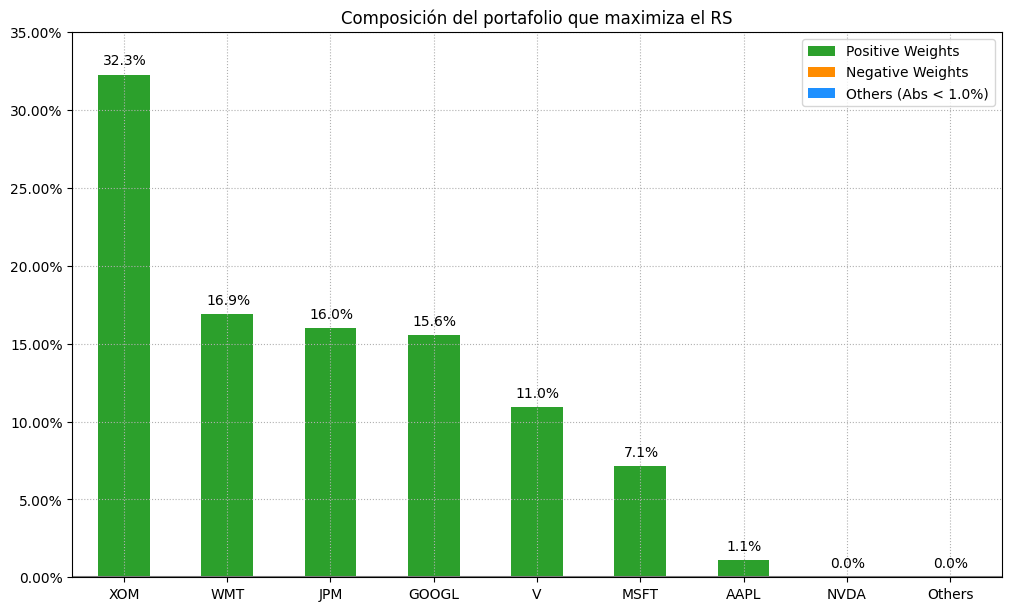

In [8]:
rp.plot_bar(w = w_mv_sharpe,
            title="Composición del portafolio que maximiza el RS")
plt.show()

In [9]:
w_mv_sharpe

,weights
AAPL,1.107877e-02
MSFT,7.131539e-02
NVDA,1.614017e-08
AMZN,8.203744e-09
GOOGL,1.555693e-01
META,4.980496e-09
JPM,1.603336e-01
V,1.095851e-01
WMT,1.693002e-01
XOM,3.228177e-01


In [10]:
cov_mat = returns.cov()

Dado que vamos a simular el comportamiento del portafolio, debemos de tener en cuenta la estructura de correlaciones entre los activos que hacen parte del portafolio al momento de hacer la simulación. Esto implica que debemos usar una distribución que permita tener en cuenta las correlaciones que existen entre los activos. Para nuestro caso vamos a emplear la descomposición de Cholesky. Esta descomposición la emplearemos después en la simulación del comportamiento de los precios de las acciones.

In [11]:
chol_mat = np.linalg.cholesky(cov_mat)

In [12]:
np.random.seed(42)
rv = np.random.normal(size=(N_SIMS, len(RISKY_ASSETS)))
correlated_rv = np.transpose(
    np.matmul(chol_mat, np.transpose(rv))
)

Ahora definamos las medidas a emplear en la simulación.

In [13]:
PROP = w_mv_sharpe.values.T
r = np.mean(returns, axis=0).values # Medias de los retornos
sigma = np.std(returns, axis=0).values # Desviaciones estándar de los retornos
S_0 = df["Adj Close"][RISKY_ASSETS].values[-1, :] # Precio de cierre del ultimo dia registrado
SHARES = P_0 * (PROP / S_0) # Cantidad de acciones a comprar

Simulemos el precio final de las acciones

In [14]:
PROP

array([[1.10787679e-02, 7.13153853e-02, 1.61401718e-08, 8.20374362e-09,
        1.55569268e-01, 4.98049577e-09, 1.60333551e-01, 1.09585074e-01,
        1.69300203e-01, 3.22817721e-01]])

In [15]:
S_T = S_0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * correlated_rv)

In [16]:
S_T.shape

(100000, 10)

Y el precio final de nuestro portafolio, ademas de la diferencia entre el precio final y nuestra inversión.

In [17]:
P_T = np.sum(SHARES * S_T, axis=1)
P_diff = P_T - P_0

In [18]:
cambio = P_diff.mean()
retorno = cambio / P_0
anualizado = ((1 + retorno) ** 252) - 1
print(f"La ganancia promedio del portafolio es un dia es de: ${cambio:.2f}, equivalente a un retorno de {retorno*100:.2f}% ({anualizado*100:.2f}% EA)")

La ganancia promedio del portafolio es un dia es de: $70.97, equivalente a un retorno de 0.07% (19.58% EA)


Con estos datos podemos calcular cual es el valor en riesgo y la perdida esperada de nuestro portafolio a un dia

In [19]:
percentiles = [0.01, 0.1, 1.] # Niveles de VaR (En %)
var = np.percentile(P_diff, percentiles)
for x, y in zip(percentiles, var):
    print(f'VaR a 1 dia al {100-x}%: ${-y:.2f}')

VaR a 1 dia al 99.99%: $-13.34
VaR a 1 dia al 99.9%: $-23.23
VaR a 1 dia al 99.0%: $-34.54


In [20]:
for x, y in zip(percentiles, var):
    expected_shortfall = P_diff[P_diff<=y].mean()
    print(f'Expected Shortfall a 1 dia al {x}%: ${-expected_shortfall:.2f}')

Expected Shortfall a 1 dia al 0.01%: $-11.10
Expected Shortfall a 1 dia al 0.1%: $-19.21
Expected Shortfall a 1 dia al 1.0%: $-29.46


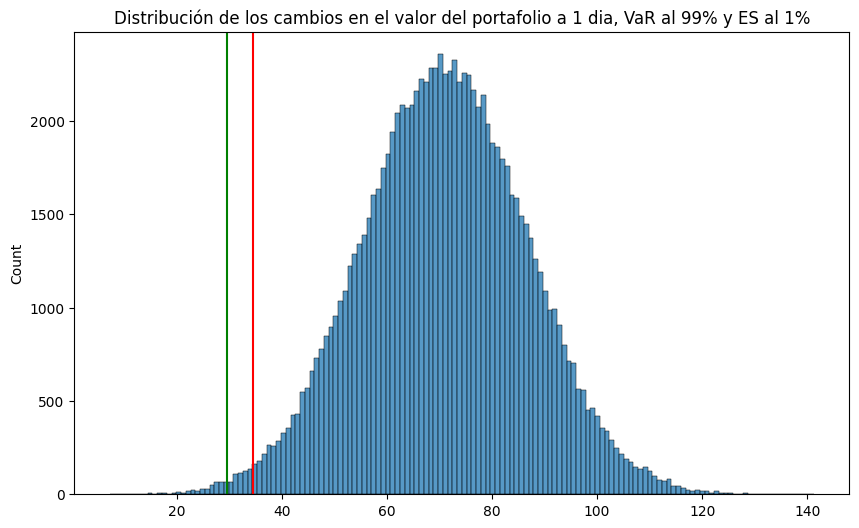

In [21]:
plt.figure(figsize=(10, 6))
ax = sns.histplot(P_diff, bins = "auto")
ax.set_title("Distribución de los cambios en el valor del portafolio a 1 dia, VaR al 99% y ES al 1%")
ax.axvline(var[2], 0, 10000, color="red")
ax.axvline(expected_shortfall, 0, 10000, color="green")
plt.show()

# Probando escenarios de cambios en los resultados de las empresas

Vamos a ver que sucede si hay un cambio ligero en los retornos de una de las acciones (o varias de las acciones)

Vamos a suponer que el retorno diario de la acción de intel aumenta en 0.1 puntos porcentuales. Debemos tener en cuenta que, dada las estructuras de correlaciones, el cambio también afecta a AMD. Para aplicar la relación usamos la matriz de rastreo de Black Litterman.

$$
\text{BLT} = \left [ \begin{array}{cccc} 
  \frac{Cov(r_1r_1)}{Var(r_1)} & \frac{Cov(r_1r_2)}{Var(r_2)} & \cdots & \frac{Cov(r_1r_k)}{Var(r_k)} \\
  \frac{Cov(r_2r_1)}{Var(r_1)} & \frac{Cov(r_2r_2)}{Var(r_2)} & \cdots & \frac{Cov(r_2r_k)}{Var(r_k)} \\
  \vdots & \vdots & \ddots & \cdots \\
  \frac{Cov(r_kr_1)}{Var(r_1)} & \frac{Cov(r_kr_2)}{Var(r_2)} & \cdots & \frac{Cov(r_kr_k)}{Var(r_k)}
\end{array} \right ] = 
\left [ \begin{array}{cccc} 
  1 & \frac{\sigma_{12}}{\sigma^2_{2}} & \cdots & \frac{\sigma_{1k}}{\sigma^2_{k}} \\
  \frac{\sigma_{21}}{\sigma^2_{1}} & 1 & \cdots & \frac{\sigma_{2k}}{\sigma^2_{k}} \\
  \vdots & \vdots & \ddots & \cdots \\
  \frac{\sigma_{k1}}{\sigma^2_{1}} & \frac{\sigma_{k2}}{\sigma^2_{2}} & \cdots & 1
\end{array} \right ]
$$

In [22]:
delta = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0.001])
BLT = cov_mat/np.diag(cov_mat)
r_ajustado = np.array(r + np.matmul(BLT, np.transpose(delta)))

In [23]:
rv = np.random.normal(size=(N_SIMS, len(RISKY_ASSETS)))
correlated_rv = np.transpose(
    np.matmul(chol_mat, np.transpose(rv))
)

S_T_ajustado = S_0 * np.exp((r_ajustado - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * correlated_rv)

P_T_ajustado = np.sum(SHARES * S_T_ajustado, axis=1)
P_diff_ajustado = P_T_ajustado - P_0

cambio_ajustado = P_diff_ajustado.mean()
retorno_ajustado = cambio_ajustado / P_0
anualizado_ajustado = ((1 + retorno_ajustado) ** 252) - 1
print(f"La ganancia promedio del portafolio es un dia es de: ${cambio_ajustado:.2f}, equivalente a un retorno de {retorno_ajustado*100:.2f}% ({anualizado_ajustado*100:.2f}% EA)")

La ganancia promedio del portafolio es un dia es de: $105.80, equivalente a un retorno de 0.11% (30.54% EA)


In [24]:
percentiles = [0.01, 0.1, 1.]
var_ajustado = np.percentile(P_diff_ajustado, percentiles)
for x, y in zip(percentiles, var_ajustado):
    print(f'VaR a 1 dia al {100-x}%: ${-y:.2f}')

VaR a 1 dia al 99.99%: $-46.84
VaR a 1 dia al 99.9%: $-56.82
VaR a 1 dia al 99.0%: $-69.21


In [25]:
for x, y in zip(percentiles, var_ajustado):
    expected_shortfall_ajustado = P_diff_ajustado[P_diff_ajustado<=y].mean()
    print(f'Expected Shortfall a 1 dia al {x}%: ${-expected_shortfall_ajustado:.2f}')

Expected Shortfall a 1 dia al 0.01%: $-41.93
Expected Shortfall a 1 dia al 0.1%: $-52.76
Expected Shortfall a 1 dia al 1.0%: $-63.83


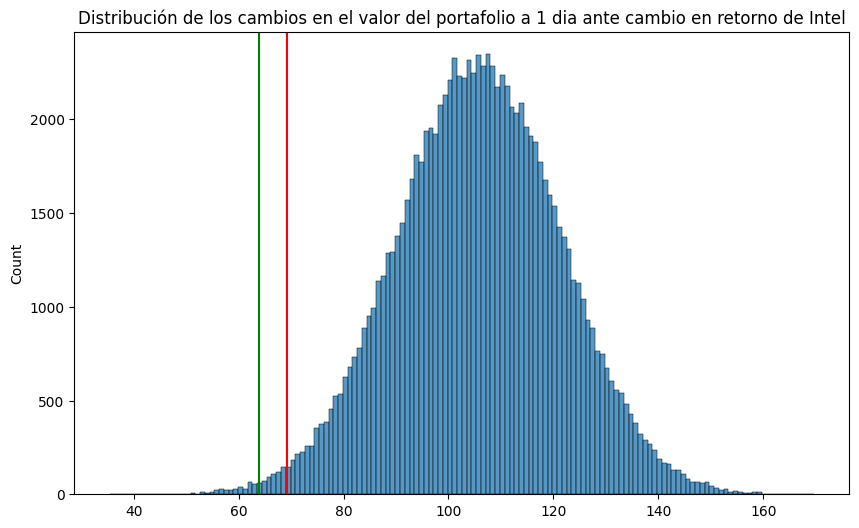

In [26]:
plt.figure(figsize=(10, 6))
ax = sns.histplot(P_diff_ajustado, bins = "auto")
ax.set_title("Distribución de los cambios en el valor del portafolio a 1 dia ante cambio en retorno de Intel")
ax.axvline(var_ajustado[2], 0, 10000, color="red")
ax.axvline(expected_shortfall_ajustado, 0, 10000, color="green")
plt.show()

# Que pasa si se tiene un evento extremo

Vamos a considerar un evento extremo, en el cual cae considerablemente el retorno esperado de la acción de Exxon.

In [27]:
delta = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, -0.15])
r_estress = np.array(r + np.matmul(BLT, np.transpose(delta)))

rv = np.random.normal(size=(N_SIMS, len(RISKY_ASSETS)))
correlated_rv = np.transpose(
    np.matmul(chol_mat, np.transpose(rv))
)

S_T_estress = S_0 * np.exp((r_estress - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * correlated_rv)

P_T_estress = np.sum(SHARES * S_T_estress, axis=1)
P_diff_estress = P_T_estress - P_0

cambio_estress = P_diff_estress.mean()
retorno_estress = cambio_estress / P_0
anualizado_estress = ((1 + retorno_estress) ** 252) - 1
print(f"La ganancia promedio del portafolio es un dia es de: ${cambio_estress:.2f}, equivalente a un retorno de {retorno_estress*100:.2f}% ({anualizado_estress*100:.2f}% EA)")

La ganancia promedio del portafolio es un dia es de: $-4787.72, equivalente a un retorno de -4.79% (-100.00% EA)


In [28]:
percentiles = [0.01, 0.1, 1.]
var_estress = np.percentile(P_diff_estress, percentiles)
for x, y in zip(percentiles, var_estress):
    print(f'VaR a 1 dia al {100-x}%: ${-y:.2f}')

VaR a 1 dia al 99.99%: $4843.80
VaR a 1 dia al 99.9%: $4835.02
VaR a 1 dia al 99.0%: $4822.42


In [29]:
for x, y in zip(percentiles, var_estress):
    expected_shortfall_estress = P_diff_estress[P_diff_estress<=y].mean()
    print(f'Expected Shortfall a 1 dia al {x}%: ${-expected_shortfall_estress:.2f}')

Expected Shortfall a 1 dia al 0.01%: $4847.71
Expected Shortfall a 1 dia al 0.1%: $4838.81
Expected Shortfall a 1 dia al 1.0%: $4827.68


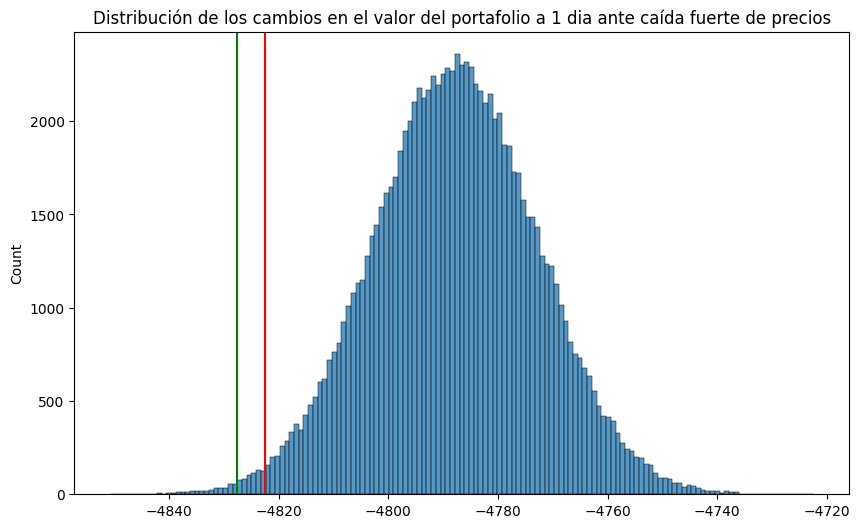

In [30]:
plt.figure(figsize=(10, 6))
ax = sns.histplot(P_diff_estress, bins = "auto")
ax.set_title("Distribución de los cambios en el valor del portafolio a 1 dia ante caída fuerte de precios")
ax.axvline(var_estress[2], 0, 10000, color="red")
ax.axvline(expected_shortfall_estress, 0, 10000, color="green")
plt.show()